# **Install**

In [ ]:
%pip install -q --upgrade jax-ai-stack optuna # Install JAX, Flax, Optax

# **Setup**

In [ ]:
import os, time, json, pickle
import jax, jax.numpy as jnp
import numpy as np
from flax import nnx
import optuna
import optax
import matplotlib.pyplot as plt
from tensorflow.keras.datasets import fashion_mnist

# Change below values for the full run
QUICK = True
TEST_RUN = True

BUDGETS = [2_560, 12_800, 32_000, 64_000, 128_000]        # Training images seen per candidate during search
BATCH_SIZES = [32, 64, 128]
SEARCH_METHODS = ["GA", "MAP-Elites", "Optuna TPE", "Random search"]
SEEDS = [0, 1] if QUICK else [0, 1, 2, 3, 4]
CPG = 24                                                  # Candidate per generation (CPG)
GENERATIONS = 5 if QUICK else 20                          # CPG * GENERATIONS - networks per search
EVAL_EVERY = 640                                          # Evaluate every 640 images
THRESHOLD = [0.75, 0.80, 0.85]                            # speed - accuracy models need to reach

TOP_K, RECHECK_SEEDS = 5, 3
EPOCHS = 2 if QUICK else 20
N_TRAIN = 50_000
SPLIT_SEED = 42
DATA_SEED = 1234
SGD_MOMENTUM = 0.9

# Search space - genes and their ranges
SEARCH_SPACE = {
    "lr": ("log", 1e-4, 1.0),
    "optimizer": ("choice", ["sgd", "adam"]),
    "batch_size": ("choice", BATCH_SIZES),
    "layers": ("choice", [1, 2, 3]),                    # number of hidden Dense layers
    "width": ("int", 16, 256),                          # units per hidden layer
    "activation": ("choice", ["relu", "tanh"]),
}

if TEST_RUN:
    BUDGETS, SEEDS, GENERATIONS, TOP_K, RECHECK_SEEDS = [2_560], [0], 2, 3, 1

# Baseline models
BASELINES = {
    "Adam 1e-3": dict(lr=1e-3, optimizer="adam", batch_size=128, layers=2, width=128, activation="relu"),
    "Adam 3e-4": dict(lr=3e-4, optimizer="adam", batch_size=128, layers=2, width=128, activation="relu"),
    "SGD 1e-2":  dict(lr=1e-2, optimizer="sgd",  batch_size=128, layers=2, width=128, activation="relu"),
}
N_GENES = len(SEARCH_SPACE)

def decode(genome):
    """Genome -> decode -> Hyperparameters"""
    g = np.clip(np.asarray(genome, dtype=float), 0.0, 1.0)
    hp = {}
    for x, (name, spec) in zip(g, SEARCH_SPACE.items()):
        kind = spec[0]
        if kind == "log":
            lo, hi = np.log10(spec[1]), np.log10(spec[2])
            hp[name] = float(10 ** (lo + x * (hi - lo)))
        elif kind == "int":
            hp[name] = int(round(spec[1] + x * (spec[2] - spec[1])))
        else:
            options = spec[1]
            hp[name] = options[min(int(x * len(options)), len(options) - 1)]
    return hp

def encode(hp):
    """Hyperparameters -> encode -> Genome"""
    g = []
    for name, spec in SEARCH_SPACE.items():
        kind, v = spec[0], hp[name]
        if kind == "log":
            lo, hi = np.log10(spec[1]), np.log10(spec[2])
            g.append((np.log10(v) - lo) / (hi - lo))
        elif kind == "int":
            g.append((v - spec[1]) / (spec[2] - spec[1]))
        else:
            options = spec[1]
            g.append((options.index(v) + 0.5) / len(options))
    return np.array(g)

def describe(hp):
    return (f"{hp['optimizer']:<4} lr={hp['lr']:.4f} batch={hp['batch_size']:3d} "
            f"{hp['layers']}x{hp['width']:3d} {hp['activation']}")

def n_params(hp, n_in=784, n_out=10):
    w, L = hp["width"], hp["layers"]
    return n_in * w + w + (L - 1) * (w * w + w) + w * n_out + n_out



# MAP-Elites (Learning rate * Number of network parameters)
GRID_BINS = 8
GOOD_CELL_MARGIN = 0.03
_P_MIN = n_params(dict(width=16, layers=1))
_P_MAX = n_params(dict(width=256, layers=3))

def grid_cell(hp):
    """Return the (row, col) cell of the diversity grid for one network."""
    lr_pos = (np.log10(hp["lr"]) + 4) / 4  # 0..1
    size_pos = (np.log10(n_params(hp)) - np.log10(_P_MIN)) / (np.log10(_P_MAX) - np.log10(_P_MIN))
    to_bin = lambda p: int(np.clip(p * GRID_BINS, 0, GRID_BINS - 1))
    return to_bin(lr_pos), to_bin(size_pos)

def sample_order(n_samples, seed=DATA_SEED):
    """Order of training images: identical for every network. Reshuffles each epoch,
    so budgets larger than 50,000 images work."""
    rng = np.random.default_rng(seed)
    n_epochs = -(-n_samples // N_TRAIN)
    return np.concatenate([rng.permutation(N_TRAIN) for _ in range(n_epochs)])[:n_samples]

print("JAX backend:", jax.default_backend(), "| devices:", jax.devices())


/usr/local/lib/python3.13/dist-packages/jaxlib/plugin_support.py:71: RuntimeWarning: JAX plugin jax_cuda13_plugin version 0.11.1 is installed, but it is not compatible with the installed jaxlib version 0.8.0, so it will not be used.
  warnings.warn(
ERROR:2026-10-30 08:33:18,135:jax._src.xla_bridge:473: Jax plugin configuration error: Exception when calling jax_plugins.xla_cuda13.initialize()
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/jax/_src/xla_bridge.py", line 471, in discover_pjrt_plugins
    plugin_module.initialize()
    ~~~~~~~~~~~~~~~~~~~~~~~~^^
  File "/usr/local/lib/python3.13/dist-packages/jax_plugins/xla_cuda13/__init__.py", line 378, in initialize
    xla_client.register_custom_type_handler(
    ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
AttributeError: module 'jaxlib.xla_client' has no attribute 'register_custom_type_handler'. Did you mean: 'register_custom_type_id_handler'?
ERROR:jax._src.xla_bridge:Jax plugin configuration error: Ex

JAX backend: gpu | devices: [CudaDevice(id=0)]


# **Load Data**

In [ ]:
#Loading data
(x_train, y_train), (x_test, y_test) = fashion_mnist.load_data()

# Normalize images to [0, 1]
x_train = x_train.astype(np.float32) / 255.0
x_test = x_test.astype(np.float32) / 255.0

# Create a fixed 50k/10k training-validation split
rng = np.random.default_rng(42)
indices = rng.permutation(len(x_train))

train_idx = indices[:50000]
val_idx = indices[50000:]

x_val, y_val = x_train[val_idx], y_train[val_idx]
x_train, y_train = x_train[train_idx], y_train[train_idx]

# Flatten 28x28 images
x_train = jnp.asarray(x_train.reshape(-1, 784))
x_val = jnp.asarray(x_val.reshape(-1, 784))
x_test = jnp.asarray(x_test.reshape(-1, 784))

y_train = jnp.asarray(y_train)
y_val = jnp.asarray(y_val)
y_test = jnp.asarray(y_test)

print("Training:", x_train.shape)
print("Validation:", x_val.shape)
print("Test:", x_test.shape)


Training: (50000, 784)
Validation: (10000, 784)
Test: (10000, 784)


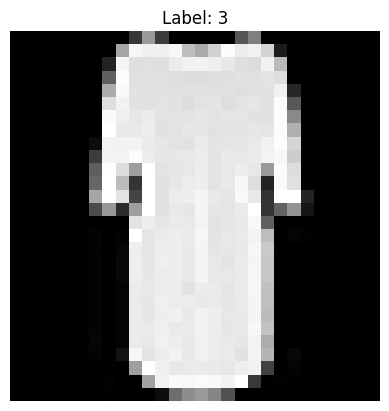

In [ ]:
#Show image
plt.imshow(x_train[0].reshape(28, 28), cmap="gray")
plt.title(f"Label: {y_train[0]}")
plt.axis("off")
plt.show()

# **Training**

In [ ]:
# TRAINING
MAX_WIDTH = SEARCH_SPACE["width"][2]
GROUP = 8

def init_params(key, width):
    """Initialize the weights and biases of the neural network."""

    # Create a separate random key for each layer
    keys = jax.random.split(key, 4)

    # Initialize weights with random values scaled by the input size
    def init_weights(key, input_size, output_size, fan_in):
        weights = jax.random.normal(key, (input_size, output_size))
        return weights / jnp.sqrt(fan_in)

    # Create weights and biases for each layer
    params = {
        "W1": init_weights(keys[0], 784, MAX_WIDTH, 784),
        "b1": jnp.zeros(MAX_WIDTH),

        "W2": init_weights(keys[1], MAX_WIDTH, MAX_WIDTH, width),
        "b2": jnp.zeros(MAX_WIDTH),

        "W3": init_weights(keys[2], MAX_WIDTH, MAX_WIDTH, width),
        "b3": jnp.zeros(MAX_WIDTH),

        "Wo": init_weights(keys[3], MAX_WIDTH, 10, width),
        "bo": jnp.zeros(10)
    }

    return params

def forward(params, config, images):
    """Run the images through the neural network."""

    # Mask neurons that are outside the selected layer width
    mask = (jnp.arange(MAX_WIDTH) < config["width"]).astype(jnp.float32)

    # Choosactivation
    def activate(values):
        return jnp.where(
            config["tanh"],
            jnp.tanh(values),
            jax.nn.relu(values)
        )

    # First hidden layer
    hidden = activate(images @ params["W1"] + params["b1"])
    hidden = hidden * mask

    # Second hidden layer
    second_layer = activate(hidden @ params["W2"] + params["b2"])
    second_layer = second_layer * mask
    hidden = jnp.where(config["layers"] >= 2, second_layer, hidden)

    # Third hidden layer
    third_layer = activate(hidden @ params["W3"] + params["b3"])
    third_layer = third_layer * mask
    hidden = jnp.where(config["layers"] >= 3, third_layer, hidden)

    # Output layer produces scores for the 10 clothing categories
    output = hidden @ params["Wo"] + params["bo"]

    return output

def accuracy(p, cfg, x, y):
    return jnp.mean(jnp.argmax(forward(p, cfg, x), axis=1) == y)

def train_net(config, key, batches, train_images, train_labels, val_images, val_labels, test_images, test_labels):
    """Train one neural network and evaluate its accuracy."""

    # network's weights and biases
    params = init_params(key, config["width"])

    # optimizers
    adam = optax.adam(config["lr"])
    sgd = optax.sgd(config["lr"], momentum=SGD_MOMENTUM)
    adam_state = adam.init(params)
    sgd_state = sgd.init(params)

    # the loss
    def loss_fn(params, images, labels):
        predictions = forward(params, config, images)
        return optax.softmax_cross_entropy_with_integer_labels(predictions, labels).mean()

    # Train on one batch
    def train_step(carry, batch_indices):
        params, adam_state, sgd_state = carry

        images = train_images[batch_indices]
        labels = train_labels[batch_indices]

        gradients = jax.grad(loss_fn)(params, images, labels)

        adam_updates, adam_state = adam.update(gradients, adam_state, params)
        sgd_updates, sgd_state = sgd.update(gradients, sgd_state, params)

        # Select the correct optimizer
        updates = jax.tree_util.tree_map(
            lambda a, b: jnp.where(config["adam"], a, b),
            adam_updates, sgd_updates
        )

        params = optax.apply_updates(params, updates)
        return (params, adam_state, sgd_state), None

    # Train on all batches and evaluate after each group
    def train_group(carry, batch_group):
        carry, _ = jax.lax.scan(train_step, carry, batch_group)
        params = carry[0]
        val_accuracy = accuracy(params, config, val_images, val_labels)
        return carry, val_accuracy

    # Store validation accuracy during training
    initial_state = (params, adam_state, sgd_state)
    final_state, learning_curve = jax.lax.scan(train_group, initial_state, batches)
    params = final_state[0]

    # Evaluate the final network
    test_accuracy = accuracy(params, config, test_images, test_labels)

    return learning_curve, test_accuracy

# vmap = train many networks at once; jit = compile. in_axes: 0 = differs per network, None = shared
train_many = jax.jit(jax.vmap(train_net, in_axes=(0, 0, None, None, None, None, None, None, None)))

def train_population(hps, budget, seed, eval_every=None):
    """Train multiple networks in parallel and return their accuracies."""

    # Prepare the training budget and image order
    eval_every = eval_every or budget
    budget = (budget // eval_every) * eval_every

    #different training seeds change the network initialization but not the image order
    image_order = sample_order(budget)
    keys = jax.random.split(jax.random.PRNGKey(seed), len(hps))

    # Store results
    val = np.zeros(len(hps))
    test = np.zeros(len(hps))
    curves = [None] * len(hps)

    #use the same training batches
    batch_sizes = sorted({hp["batch_size"] for hp in hps})

    for batch_size in batch_sizes:

        batches = jnp.asarray(image_order.reshape(budget // eval_every, eval_every // batch_size,batch_size))
        # networks that use this batch size
        network_ids = [i for i, hp in enumerate(hps) if hp["batch_size"] == batch_size]
        # Train networks in smaller groups to avoid GPU memory issues
        for start in range(0, len(network_ids), CPG):
            group_ids = network_ids[start:start + CPG]
            # Pad the group to a multiple of GROUP for parallel training
            group_size = ((len(group_ids) + GROUP - 1) // GROUP) * GROUP
            group_size = min(CPG, group_size)
            padded_ids = group_ids + [group_ids[-1]] * (group_size - len(group_ids))
            # Convert hyperparameters into JAX arrays
            config = {
              "lr": jnp.array([hps[i]["lr"] for i in padded_ids], dtype=jnp.float32),
              "adam": jnp.array([hps[i]["optimizer"] == "adam" for i in padded_ids]),
              "layers": jnp.array([hps[i]["layers"] for i in padded_ids]),
              "width": jnp.array([hps[i]["width"] for i in padded_ids]),
              "tanh": jnp.array([hps[i]["activation"] == "tanh" for i in padded_ids])
            }

            # Train the group of networks in parallel
            group_curves, group_test = train_many(config, keys[jnp.array(padded_ids)], batches, x_train, y_train, x_val, y_val, x_test, y_test)
            # Convert JAX results to NumPy
            group_curves = np.asarray(group_curves)
            group_test = np.asarray(group_test)
            # Save results in the original network order
            for position, network_id in enumerate(group_ids):
                curves[network_id] = [float(accuracy) for accuracy in group_curves[position]]
                val[network_id] = group_curves[position, -1]
                test[network_id] = group_test[position]

    return val, curves, test

def train_one(hp, budget, seed, eval_every=None):
    """Train one network. Returns (final val accuracy, learning curve)."""
    val, curves, _ = train_population([hp], budget, seed, eval_every)
    return float(val[0]), (curves[0] if eval_every else [])

def fitness(hps, budget, seed):
    """FITNESS = validation accuracy after `budget` training images, for each network."""
    return train_population(hps, budget, seed)[0]


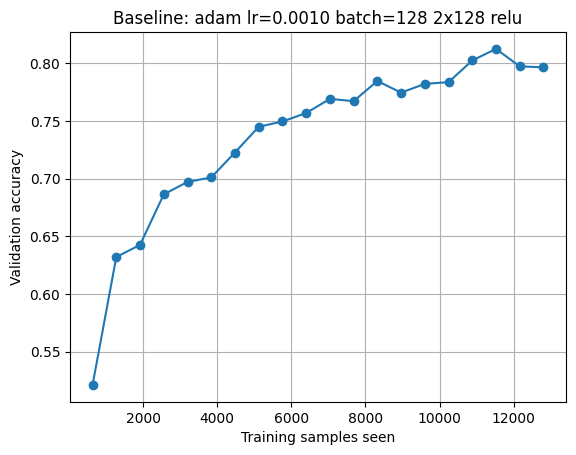

Final validation accuracy: 79.64%


In [ ]:
# Qucik model check
hp = BASELINES["Adam 1e-3"]
acc, curve = train_one(hp, budget=12_800, seed=0, eval_every=EVAL_EVERY)
samples = np.arange(1, len(curve) + 1) * EVAL_EVERY
plt.plot(samples, curve, marker="o"); plt.grid(True)
plt.xlabel("Training samples seen"); plt.ylabel("Validation accuracy")
plt.title(f"Baseline: {describe(hp)}"); plt.show()
print(f"Final validation accuracy: {acc:.2%}")

# **Search implementation**

In [ ]:
def mutate(genomes, rng, sigma=0.1):
    """add small random noise to every gene"""
    return np.clip(genomes + sigma * rng.normal(size=genomes.shape), 0.0, 1.0)

def crossover(a, b, rng):
    """Uniform crossover: every gene comes from parent a or parent b with 50% chance."""
    return np.where(rng.random(a.shape) < 0.5, a, b)

class RandomSearch:
    """Baseline search: random genomes."""
    def __init__(self, seed):
        self.rng = np.random.default_rng(seed)

    def propose(self, n):
        return self.rng.random((n, N_GENES))

    def update(self, genomes, fit):
        pass

class GA:
    """Genetic algorithm: parent selection based on accuracy, crossover and mutation"""
    def __init__(self, seed):
      self.rng = np.random.default_rng(seed)
      self.pop = None # Population
      self.fit = None # Fitness

    def propose(self, n):
      # First generation is random
      if self.pop is None:
        return self.rng.random((n, N_GENES))

      # Accuracy based selection
      w = self.fit - self.fit.min() + 1e-6
      p = w / w.sum()
      parents_a = self.pop[self.rng.choice(len(self.pop), n, p=p)]
      parents_b = self.pop[self.rng.choice(len(self.pop), n, p=p)]
      return mutate(crossover(parents_a, parents_b, self.rng), self.rng)

    def update(self, genomes, fit):
      if self.pop is None:
        self.pop, self.fit = np.array(genomes), np.array(fit)
        return

      # Competition between parent and children
      all_g = np.concatenate([self.pop, genomes])
      all_f = np.concatenate([self.fit, fit])

      # Keep the best candidates
      keep = np.argsort(all_f)[::-1][:len(genomes)]
      self.pop, self.fit = all_g[keep], all_f[keep]

class MAPElites:
    """Keeps the best network in every cell of the grid. New candidates are mutated children of random best networks."""
    def __init__(self, seed):
      self.rng = np.random.default_rng(seed)
      self.archive = {}

    def propose(self, n):
      # First generation is random
      if not self.archive:
            return self.rng.random((n, N_GENES))

      elites = np.array([g for g, f in self.archive.values()])
      parents_a = elites[self.rng.integers(len(elites), size=n)]
      parents_b = elites[self.rng.integers(len(elites), size=n)]
      return mutate(crossover(parents_a, parents_b, self.rng), self.rng)

    def update(self, genomes, fit):
      for g, f in zip(genomes, fit):
        cell = grid_cell(decode(g))
        if cell not in self.archive or f > self.archive[cell][1]:
          self.archive[cell] = (g, f)

class OptunaTPE:
    """A model based optimizer. Suggests genomes that its model thinks will score well."""
    def __init__(self, seed):
      self.study = optuna.create_study(direction="maximize", sampler=optuna.samplers.TPESampler(seed=seed))
      self.trials = []

    def propose(self, n):
      self.trials = [self.study.ask() for _ in range(n)]
      return np.array([[t.suggest_float(f"g{i}", 0.0, 1.0) for i in range(N_GENES)]for t in self.trials])

    def update(self, genomes, fit):
      for t, f in zip(self.trials, fit):
            self.study.tell(t, float(np.nan_to_num(f)))

SEARCH_CLASSES = {"GA": GA, "MAP-Elites": MAPElites, "Optuna TPE": OptunaTPE, "Random search": RandomSearch}

# **Experimental run**

In [ ]:
def run_search(method, budget, seed):
    """Shared loop for all four search methods."""
    all_genomes, all_fitness = [], []
    for gen in range(GENERATIONS):
        # picks 24 candidates
        genomes = method.propose(CPG)
        hps = [decode(g) for g in genomes]

        # train + measure
        fit = fitness(hps, budget, seed)

         # learn from results
        method.update(genomes, fit)
        all_genomes += list(genomes); all_fitness += list(fit)
    return np.array(all_genomes), np.array(all_fitness)

runs = []
t0 = time.time()
for budget in BUDGETS:
    for name, Method in SEARCH_CLASSES.items():
        for seed in SEEDS:
            t = time.time()
            G, F = run_search(Method(seed), budget, seed)

            # re-check the TOP_K best with new seeds; the best average is the winner
            top = G[np.argsort(F)[::-1][:TOP_K]]
            top_hps = [decode(g) for g in top]
            recheck = np.mean([fitness(top_hps, budget, seed=1000 + 10 * seed + r)
                               for r in range(RECHECK_SEEDS)], axis=0)
            winner = top[np.argmax(recheck)]

            runs.append(dict(budget=budget, method=name, seed=seed, genomes=G, fitness=F,
                             winner=winner, winner_recheck=float(recheck.max())))
            print(f"budget={budget:>7} {name:<14} seed {seed}: best {F.max():.4f} "
                  f"rechecked {recheck.max():.4f} [{time.time() - t:.0f}s]  {describe(decode(winner))}")
print(f"All searches done in {time.time() - t0:.0f}s")

budget=   2560 GA             seed 0: best 0.7759 rechecked 0.7651 [20s]  adam lr=0.0058 batch= 64 2x165 tanh


[I 2026-10-30 08:33:57,447] A new study created in memory with name: no-name-c68c9fdf-979a-44d7-bd80-e159e6e695f8


budget=   2560 MAP-Elites     seed 0: best 0.7640 rechecked 0.7669 [8s]  adam lr=0.0058 batch= 64 2x165 tanh
budget=   2560 Optuna TPE     seed 0: best 0.7760 rechecked 0.7826 [5s]  adam lr=0.0048 batch= 64 1x181 tanh
budget=   2560 Random search  seed 0: best 0.7640 rechecked 0.7731 [1s]  adam lr=0.0038 batch= 64 2x 63 tanh
All searches done in 34s


In [ ]:
# RETRAIN WINNER
FINAL_SEEDS = 3

# Networks to retrain: the baselines + one winner from every search run
networks = []
for name, hp in BASELINES.items():
    networks.append({"name": "Baseline " + name, "method": "Baseline", "budget": None, "hp": hp})
for run in runs:
    name = f"{run['method']} B={run['budget']} s{run['seed']}"
    networks.append({"name": name, "method": run["method"], "budget": run["budget"], "hp": decode(run["winner"])})

all_hps = [net["hp"] for net in networks]
all_curves = []
all_test_accuracies = []

t0 = time.time()
for s in range(FINAL_SEEDS):
    _, curves, test_accuracies = train_population(all_hps, EPOCHS * N_TRAIN, seed=500 + s, eval_every=EVAL_EVERY)
    all_curves.append(curves)
    all_test_accuracies.append(test_accuracies)
    print(f"Seed {s + 1}/{FINAL_SEEDS} done [{time.time() - t0:.0f}s]")

# Store individual learning curves and their average
for i, net in enumerate(networks):
    net["seed_curves"] = np.array([all_curves[s][i] for s in range(FINAL_SEEDS)])
    net["curve"] = net["seed_curves"].mean(axis=0)

    net["test_accuracy"] = np.mean([all_test_accuracies[s][i] for s in range(FINAL_SEEDS)])

Seed 1/3 done [16s]
Seed 2/3 done [25s]
Seed 3/3 done [34s]


# **Evaluation**

In [ ]:
# Speed - number of training images a network needs to reach 75%, 80% and 85% accuracy.

def images_to_reach(curve, threshold):
    """Images seen when the curve first reaches the threshold."""
    for i, acc in enumerate(curve):
        if acc >= threshold:
            return (i + 1) * EVAL_EVERY
    return np.inf

# Calculate learning speed for each seed separately
for net in networks:
    net["seed_speeds"] = {}
    net["speed"] = {}

    for threshold in THRESHOLD:
        # Calculate how many images each seed needs
        speeds = []

        for curve in net["seed_curves"]:
            images = images_to_reach(curve, threshold)
            speeds.append(images)

        # Store individual results and their average
        net["seed_speeds"][threshold] = speeds
        net["speed"][threshold] = np.mean(speeds)


baselines = [net for net in networks if net["method"] == "Baseline"]
winners = [net for net in networks if net["method"] != "Baseline"]

# Table: images needed by every network
print(f"{'Network':<28} {'to 75%':>8} {'to 80%':>8} {'to 85%':>8}   Hyperparameters")
for net in networks:
    speeds = " ".join(f"{s:>8,.0f}" if s < np.inf else f"{'never':>8}" for s in net["speed"].values())
    print(f"{net['name']:<28} {speeds}   {describe(net['hp'])}")

Network                        to 75%   to 80%   to 85%   Hyperparameters
Baseline Adam 1e-3              6,827   11,307   44,373   adam lr=0.0010 batch=128 2x128 relu
Baseline Adam 3e-4             11,733   21,120   91,093   adam lr=0.0003 batch=128 2x128 relu
Baseline SGD 1e-2              14,720   23,040    never   sgd  lr=0.0100 batch=128 2x128 relu
GA B=2560 s0                    2,133   10,027    never   adam lr=0.0058 batch= 64 2x165 tanh
MAP-Elites B=2560 s0            2,560   10,453    never   adam lr=0.0058 batch= 64 2x165 tanh
Optuna TPE B=2560 s0            2,347    5,760   43,307   adam lr=0.0048 batch= 64 1x181 tanh
Random search B=2560 s0         2,560    5,547   45,013   adam lr=0.0038 batch= 64 2x 63 tanh


In [ ]:
import pandas as pd

# Collect the winning accuracy from each experiment
results = []

for run in runs:
    results.append({
        "Budget": run["budget"],
        "Method": run["method"],
        "Seed": run["seed"],
        "Accuracy": run["winner_recheck"]
    })

results_df = pd.DataFrame(results)

# Compare methods using the same budget and seed
comparison = results_df.pivot(
    index=["Budget", "Seed"],
    columns="Method",
    values="Accuracy"
)

display(comparison)

,Method,GA,MAP-Elites,Optuna TPE,Random search
Budget,Seed,,,,
2560,0,0.7651,0.7669,0.7826,0.7731


In [ ]:
from scipy.stats import wilcoxon

# Compare each method against Random Search
for budget in BUDGETS:
    data = comparison.loc[budget]

    for method in ["GA", "MAP-Elites", "Optuna TPE"]:
        differences = data[method] - data["Random search"]

        # Test whether the methods have different accuracies
        if np.allclose(differences, 0):
            p_value = 1.0
        else:
            p_value = wilcoxon(differences).pvalue

        print(f"Budget {budget}, {method}: p = {p_value:.4f}")

Budget 2560, GA: p = 1.0000
Budget 2560, MAP-Elites: p = 1.0000
Budget 2560, Optuna TPE: p = 1.0000


# Evolution

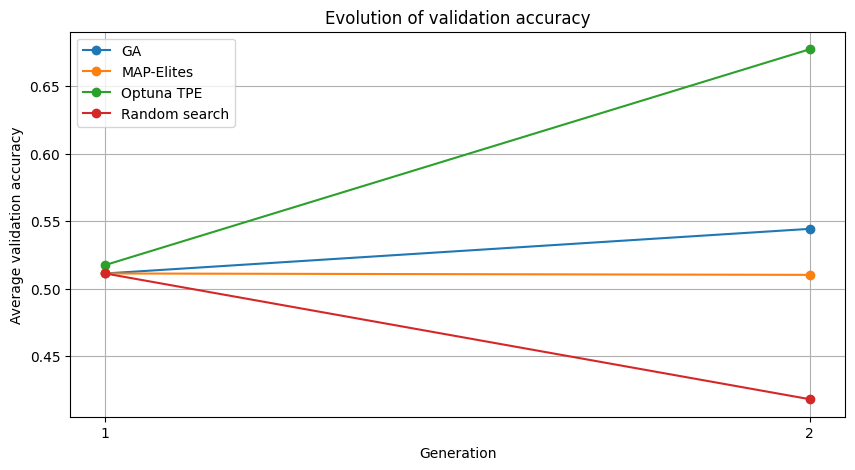

In [ ]:
# Compare how the search methods improve over generations
plt.figure(figsize=(10, 5))

for run in runs:
    if run["budget"] != BUDGETS[0] or run["seed"] != SEEDS[0]:
        continue

    # Get the accuracy of all networks in each generation
    scores = run["fitness"].reshape(GENERATIONS, CPG)
    # Calculate the average accuracy for each generation
    average_accuracy = scores.mean(axis=1)

    plt.plot(range(1, GENERATIONS + 1), average_accuracy, marker="o", label=run["method"])

plt.xlabel("Generation")
plt.ylabel("Average validation accuracy")
plt.title("Evolution of validation accuracy")
plt.xticks(range(1, GENERATIONS + 1))
plt.legend()
plt.grid(True)
plt.show()

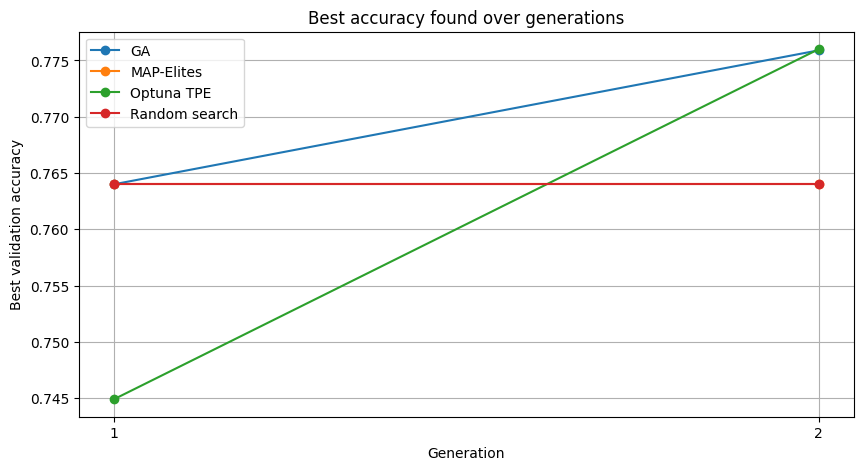

In [ ]:
# Compare the best networks found over generations
plt.figure(figsize=(10, 5))

for run in runs:
    if run["budget"] != BUDGETS[0] or run["seed"] != SEEDS[0]:
        continue

    scores = run["fitness"].reshape(GENERATIONS, CPG)
    # Best accuracy in each generation
    best = scores.max(axis=1)
    # Keep the best accuracy found so far
    best_so_far = np.maximum.accumulate(best)
    plt.plot(range(1, GENERATIONS + 1), best_so_far, marker="o", label=run["method"])

plt.xlabel("Generation")
plt.ylabel("Best validation accuracy")
plt.title("Best accuracy found over generations")
plt.xticks(range(1, GENERATIONS + 1))
plt.legend()
plt.grid(True)
plt.show()

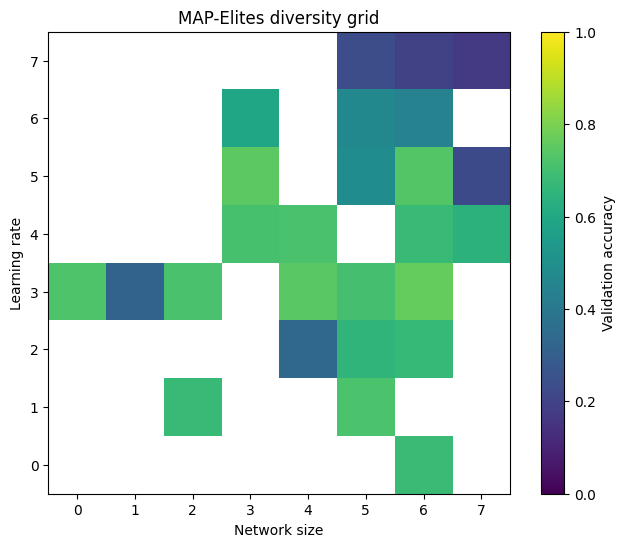

Occupied cells: 26


In [ ]:
# Select MAP-Elites results
map_run = next(run for run in runs if run["method"] == "MAP-Elites")

# Create an empty diversity grid
grid = np.full((GRID_BINS, GRID_BINS), np.nan)

# Store the best accuracy found in each cell
for genome, score in zip(map_run["genomes"], map_run["fitness"]):
    row, col = grid_cell(decode(genome))

    if np.isnan(grid[row, col]) or score > grid[row, col]:
        grid[row, col] = score

# Display the grid
plt.figure(figsize=(8, 6))
plt.imshow(grid, origin="lower", vmin=0, vmax=1)
plt.colorbar(label="Validation accuracy")
plt.xlabel("Network size")
plt.ylabel("Learning rate")
plt.title("MAP-Elites diversity grid")
plt.show()

print("Occupied cells:", np.count_nonzero(~np.isnan(grid)))

In [ ]:
occupied = np.count_nonzero(~np.isnan(grid))
coverage = occupied / grid.size

print(f"Grid coverage: {coverage:.1%}")

# Sum the best accuracies of all occupied grid cells
qd_score = np.nansum(grid)
print(f"QD-score: {qd_score:.4f}")

Grid coverage: 40.6%
QD-score: 14.7363


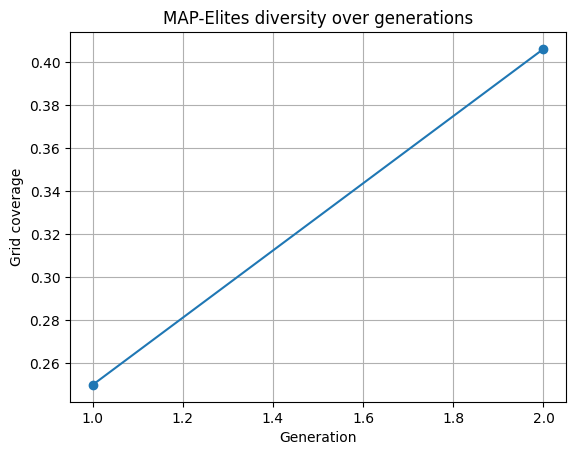

In [ ]:
# Track MAP-Elites grid coverage over generations
occupied_cells = set()
coverage = []

for genome in map_run["genomes"]:
    occupied_cells.add(grid_cell(decode(genome)))
    coverage.append(len(occupied_cells) / GRID_BINS**2)

# Plot coverage after each generation
coverage_per_generation = np.array(coverage)[CPG - 1::CPG]

plt.plot(range(1, GENERATIONS + 1), coverage_per_generation, marker="o")
plt.xlabel("Generation")
plt.ylabel("Grid coverage")
plt.title("MAP-Elites diversity over generations")
plt.grid(True)
plt.show()

# **Analysis**


Reach 75%: best baseline needs 6,827 images
  GA             budget   2,560: 1/1 faster
  MAP-Elites     budget   2,560: 1/1 faster
  Optuna TPE     budget   2,560: 1/1 faster
  Random search  budget   2,560: 1/1 faster

Reach 80%: best baseline needs 11,307 images
  GA             budget   2,560: 1/1 faster
  MAP-Elites     budget   2,560: 1/1 faster
  Optuna TPE     budget   2,560: 1/1 faster
  Random search  budget   2,560: 1/1 faster

Reach 85%: best baseline needs 44,373 images
  GA             budget   2,560: 0/1 faster
  MAP-Elites     budget   2,560: 0/1 faster
  Optuna TPE     budget   2,560: 1/1 faster
  Random search  budget   2,560: 0/1 faster


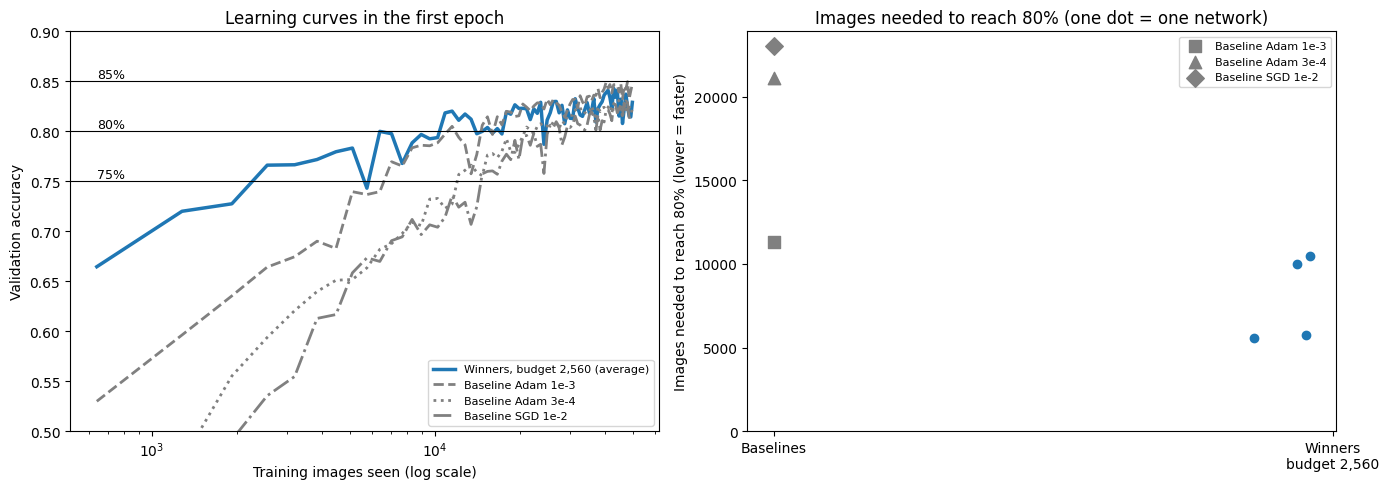

In [ ]:
def fast_learner_test(group, threshold):
    """Count how many winners learn faster than the best baseline."""

    best_baseline = min(b["speed"][threshold] for b in baselines)

    faster_winners = 0
    for winner in group:
        if winner["speed"][threshold] < best_baseline:
            faster_winners += 1

    return faster_winners

for threshold in THRESHOLD:
    best_baseline = min(b["speed"][threshold] for b in baselines)
    print(f"\nReach {threshold:.0%}: best baseline needs {best_baseline:,.0f} images")

    for budget in BUDGETS:
        for method in ["GA", "MAP-Elites", "Optuna TPE", "Random search"]:
            group = [w for w in winners if w["budget"] == budget and w["method"] == method]

            faster = fast_learner_test(group, threshold)
            print(f"  {method:<14} budget {budget:>7,}: {faster}/{len(group)} faster")

#  Plots
images = np.arange(1, len(networks[0]["curve"]) + 1) * EVAL_EVERY
first_epoch = images <= N_TRAIN
budget_colors = ["tab:blue", "tab:orange", "tab:green", "tab:red", "tab:purple"]
baseline_styles = ["--", ":", "-."]

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

# Left plot
for B, color in zip(BUDGETS, budget_colors):
    mean_curve = np.mean([w["curve"] for w in winners if w["budget"] == B], axis=0)
    ax1.plot(images[first_epoch], mean_curve[first_epoch], color=color, linewidth=2.5,
             label=f"Winners, budget {B:,} (average)")
for b, style in zip(baselines, baseline_styles):
    ax1.plot(images[first_epoch], b["curve"][first_epoch], color="gray", linestyle=style, linewidth=2,
             label=b["name"])
for th in THRESHOLD:
    ax1.axhline(th, color="black", linewidth=0.8)
    ax1.text(images[0], th + 0.003, f"{th:.0%}", fontsize=9)
ax1.set_xscale("log")
ax1.set_ylim(0.5, 0.9)
ax1.set_xlabel("Training images seen (log scale)")
ax1.set_ylabel("Validation accuracy")
ax1.set_title("Learning curves in the first epoch")
ax1.legend(fontsize=8, loc="lower right")

# Right plot
for b, marker in zip(baselines, ["s", "^", "D"]):
    ax2.scatter(0, b["speed"][0.80], color="gray", marker=marker, s=80, label=b["name"])
for i, (B, color) in enumerate(zip(BUDGETS, budget_colors), start=1):
    speeds = [w["speed"][0.80] for w in winners if w["budget"] == B and w["speed"][0.80] < np.inf]
    x = i + np.random.uniform(-0.15, 0.15, len(speeds))
    ax2.scatter(x, speeds, color=color)
ax2.set_xticks(range(len(BUDGETS) + 1))
ax2.set_xticklabels(["Baselines"] + [f"Winners\nbudget {B:,}" for B in BUDGETS])
ax2.set_ylim(0, None)
ax2.set_ylabel("Images needed to reach 80% (lower = faster)")
ax2.set_title("Images needed to reach 80% (one dot = one network)")
ax2.legend(fontsize=8)

plt.tight_layout()
plt.savefig("h1_results.png", dpi=150)
plt.show()


In [ ]:
# Compare the final validation accuracy of all networks
results = []

for net in networks:
    final_accuracies = net["seed_curves"][:, -1]

    results.append({
        "Network": net["name"],
        "Method": net["method"],
        "Budget": net["budget"],
        "Mean accuracy": np.mean(final_accuracies),
        "Std accuracy": np.std(final_accuracies)
    })

results_df = pd.DataFrame(results)
display(results_df)

,Network,Method,Budget,Mean accuracy,Std accuracy
0,Baseline Adam 1e-3,Baseline,NaN,0.855933,0.001812
1,Baseline Adam 3e-4,Baseline,NaN,0.847400,0.001236
2,Baseline SGD 1e-2,Baseline,NaN,0.840533,0.001721
3,GA B=2560 s0,GA,2560.0,0.823000,0.009679
4,MAP-Elites B=2560 s0,MAP-Elites,2560.0,0.817633,0.004744
5,Optuna TPE B=2560 s0,Optuna TPE,2560.0,0.842967,0.000694
6,Random search B=2560 s0,Random search,2560.0,0.848767,0.001621


In [ ]:
# Compare final validation accuracy across search methods
summary = results_df.groupby("Method")["Mean accuracy"].agg(["mean", "std"])
summary = summary * 100
display(summary.round(2))

,mean,std
Method,,
Baseline,84.80,0.77
GA,82.30,NaN
MAP-Elites,81.76,NaN
Optuna TPE,84.30,NaN
Random search,84.88,NaN


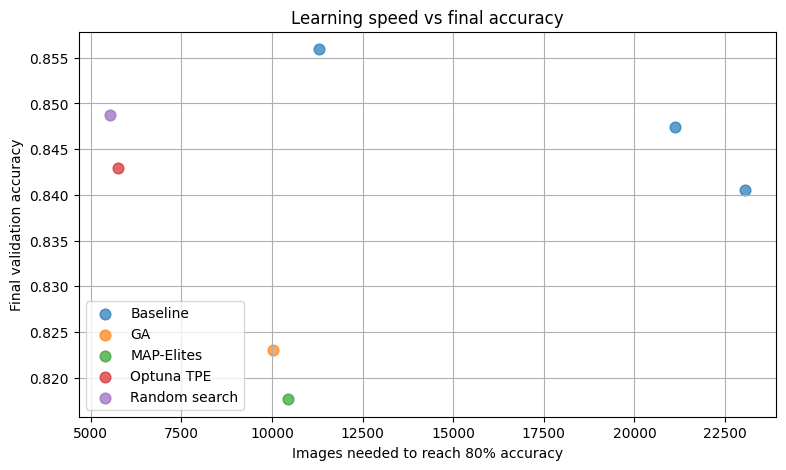

In [ ]:
# Compare learning speed with final validation accuracy
plt.figure(figsize=(9, 5))

for method in sorted(set(net["method"] for net in networks)):
    group = [net for net in networks if net["method"] == method]
    speeds = []
    accuracies = []

    for net in group:
        speed = net["speed"][0.80]

        if np.isfinite(speed):
            speeds.append(speed)
            accuracies.append(net["curve"][-1])

    plt.scatter(speeds, accuracies, label=method, s=60, alpha=0.7)

plt.xlabel("Images needed to reach 80% accuracy")
plt.ylabel("Final validation accuracy")
plt.title("Learning speed vs final accuracy")
plt.legend()
plt.grid(True)
plt.show()

In [ ]:
# Compare final test accuracy across search methods
test_df = pd.DataFrame(networks)
summary = test_df.groupby("method")["test_accuracy"].agg(["mean", "std"])

display((summary * 100).round(2))

,mean,std
method,,
Baseline,83.94,0.6
GA,81.64,NaN
MAP-Elites,80.95,NaN
Optuna TPE,83.43,NaN
Random search,83.89,NaN
